# 🍷 Wine Quality Prediction — Random Forest vs SGD vs SVC

**Objective:** train and compare three classifiers (Random Forest, Stochastic Gradient Descent, Support Vector Classifier) to predict wine quality from physicochemical properties (acidity, density, alcohol, ...).

**Dataset:** *Wine Quality – Red* (Cortez et al., 2009), 1,599 Portuguese *Vinho Verde* red wines, 11 chemical features, quality scored 0–10 by expert tasters (observed range 3–8).

**Notebook outline**
1. Load data and inspect structure
2. Class distribution of quality scores
3. Exploratory data analysis (distributions, correlation heatmap)
4. Class imbalance discussion
5. Feature engineering: binning the target
6. Stratified train/test split
7. Model training (with cross-validated tuning)
8. Evaluation: accuracy, classification report, confusion matrix
9. Random Forest feature importance
10. Model comparison table
11. Conclusion and deployment

> **How to run:** put `winequality-red.csv` in the same folder as this notebook (or in a `data/` sub-folder), install the libraries with `pip install -r req.txt`, then *Kernel → Restart & Run All*. All key choices are in the configuration cell below.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)

try:
    from IPython.display import display
except ImportError:          # lets the same code run as a plain script
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# ───────────────────────────── CONFIGURATION ─────────────────────────────
DATA_PATH       = "winequality-red.csv"
RANDOM_STATE    = 42
TEST_SIZE       = 0.20
DROP_DUPLICATES = True        # the red-wine file contains many exact duplicate rows (see section 1)
BINNING         = "binary"    # "binary"      -> bad (<=6) / good (>=7)
                              # "three_class" -> low (3-4) / medium (5-6) / high (7-8)
                              # "raw"         -> original quality scores
CV_FOLDS        = 5

## 1. Load the dataset and inspect its structure

In [2]:
def load_wine(path=DATA_PATH):
    """Load the CSV, auto-handling the ';' separator used by the UCI file."""
    for p in (Path(path), Path("data") / path):
        if p.exists():
            df = pd.read_csv(p, sep=";")
            if df.shape[1] == 1:               # wrong separator -> try comma
                df = pd.read_csv(p, sep=",")
            if "quality" not in df.columns:
                raise ValueError("Expected a 'quality' column in the dataset.")
            return df
    raise FileNotFoundError(f"Could not find '{path}'. Place it next to this notebook or in ./data/")

df_raw = load_wine()
print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")
display(df_raw.head())

Shape: 1,599 rows x 12 columns



,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print("Data types and non-null counts")
df_raw.info()
print("\nMissing values:", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
display(df_raw.describe().T.round(3))

Data types and non-null counts
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values: 0
Exact duplicate rows: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


**Observations**
- All 11 features are continuous numeric columns and there are **no missing values**, so no imputation is needed.
- Features sit on very different scales (e.g. `density` ≈ 0.99–1.00 vs `total sulfur dioxide` up to ~290). This does not matter for tree models but matters a lot for **SGD and SVC**, so those are wrapped in a `StandardScaler` pipeline.
- The file contains many **exact duplicate rows**. Many are probably different bottles/tastings with identical lab values, but if duplicates land on both sides of a train/test split the test score is inflated (the model has literally seen the row). The safer choice is to drop them before splitting; this is controlled by `DROP_DUPLICATES`.

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else df_raw.copy()
print(f"Rows before: {len(df_raw):,} | after de-duplication: {len(df):,} | removed: {len(df_raw) - len(df):,}")

features = [c for c in df.columns if c != "quality"]
X = df[features]

Rows before: 1,599 | after de-duplication: 1,359 | removed: 240


## 2. Class distribution of quality scores

,count (raw file),count (used),share (used) %
quality,,,
3,10,10,0.7
4,53,53,3.9
5,681,577,42.5
6,638,535,39.4
7,199,167,12.3
8,18,17,1.3


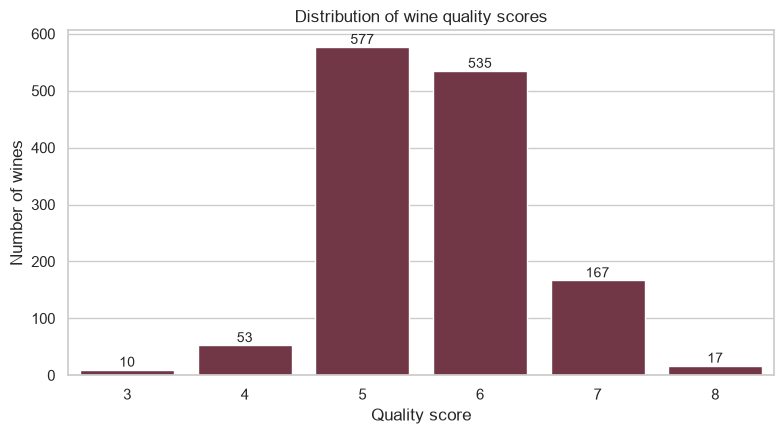

In [5]:
dist = pd.DataFrame({
    "count (raw file)": df_raw["quality"].value_counts().sort_index(),
    "count (used)":     df["quality"].value_counts().sort_index(),
})
dist["share (used) %"] = (dist["count (used)"] / dist["count (used)"].sum() * 100).round(1)
display(dist)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, x="quality", color="#7b2d43", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Distribution of wine quality scores")
ax.set_xlabel("Quality score"); ax.set_ylabel("Number of wines")
plt.tight_layout(); plt.show()

## 3. Exploratory data analysis
### 3.1 Distribution of every chemical feature

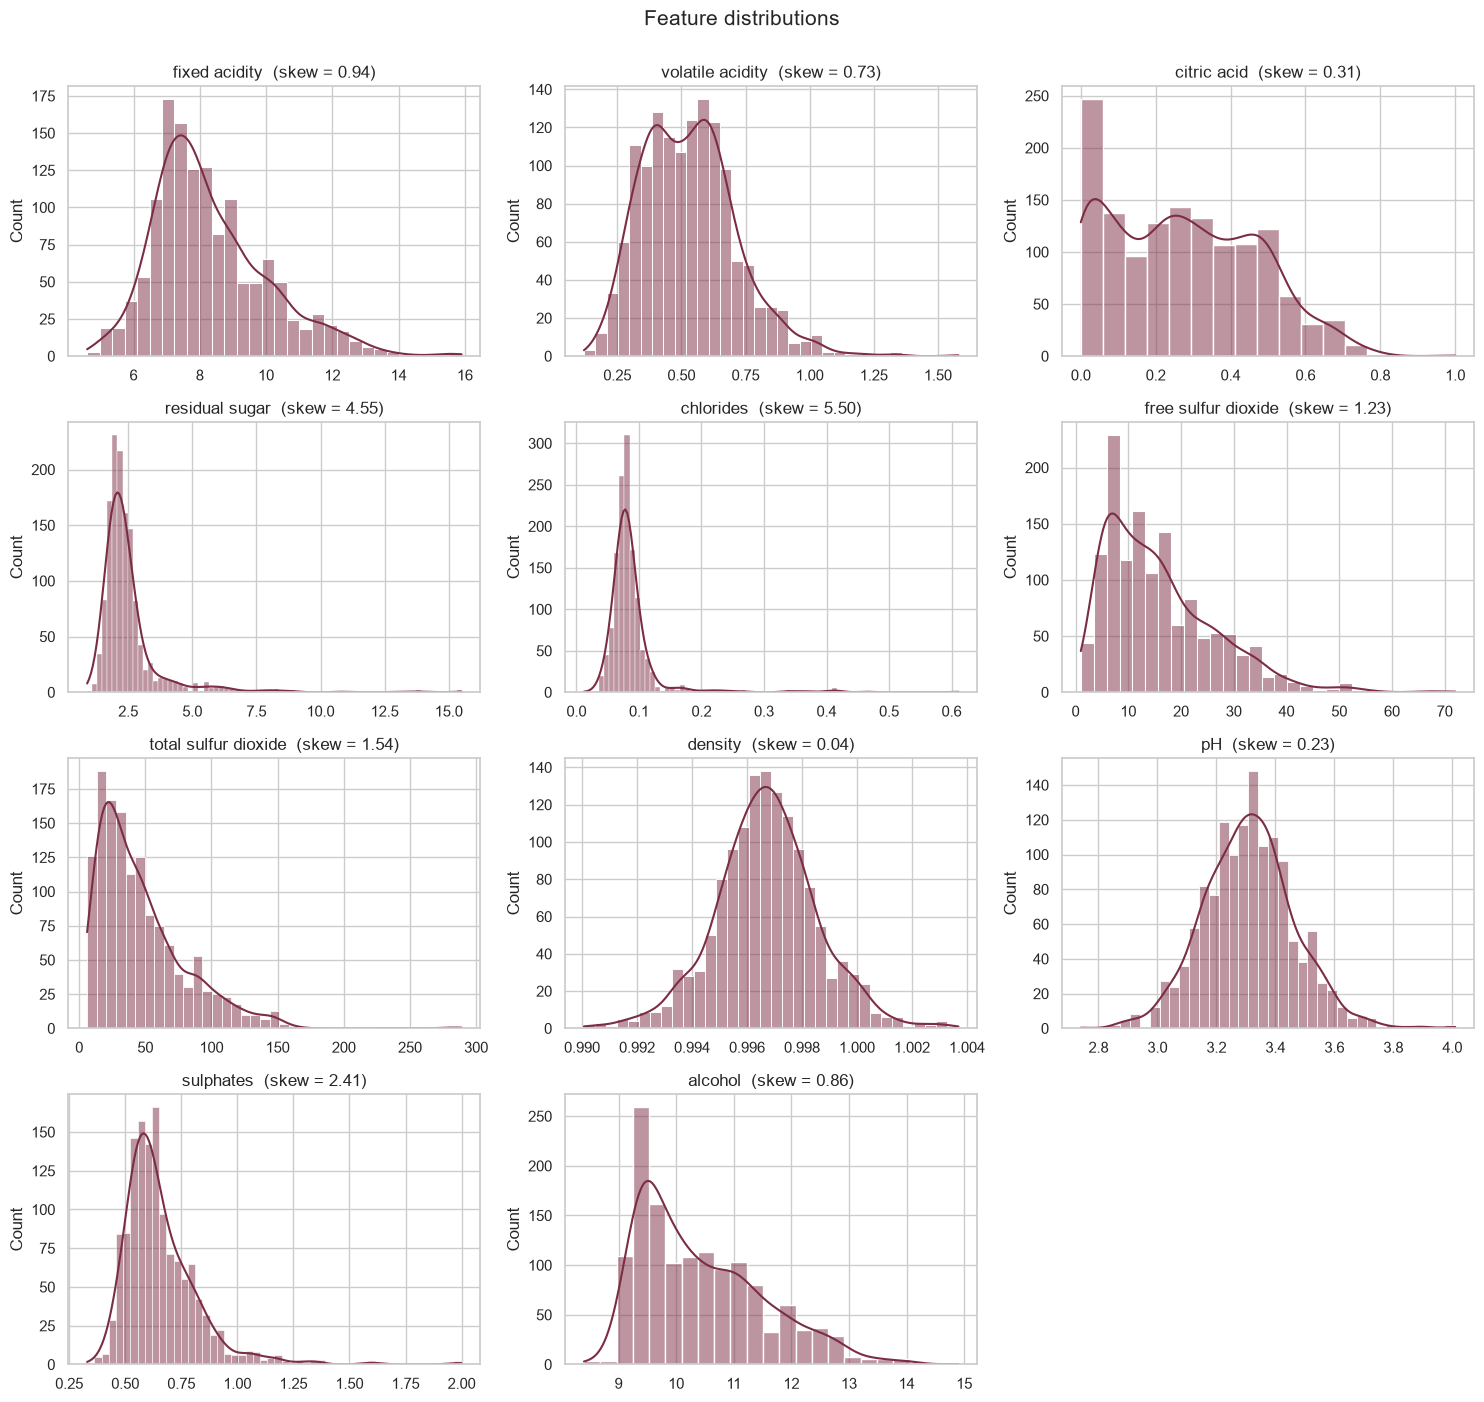

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="#7b2d43", edgecolor="white")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_xlabel("")
for ax in axes.ravel()[len(features):]:
    ax.set_visible(False)
plt.suptitle("Feature distributions", y=1.0, fontsize=15)
plt.tight_layout(); plt.show()

Several features are **strongly right-skewed with long tails** (`residual sugar` and `chlorides` have skew above 4.5, `sulphates` above 2, `total sulfur dioxide` about 1.5), reflecting a few unusually sweet, salty or heavily sulfited wines. `density` and `pH` are close to symmetric. Tree-based models are insensitive to skew and outliers; for SGD and SVC the standard scaler handles scale, though extreme outliers can still pull the decision boundary.

### 3.2 How do the key features vary with quality?

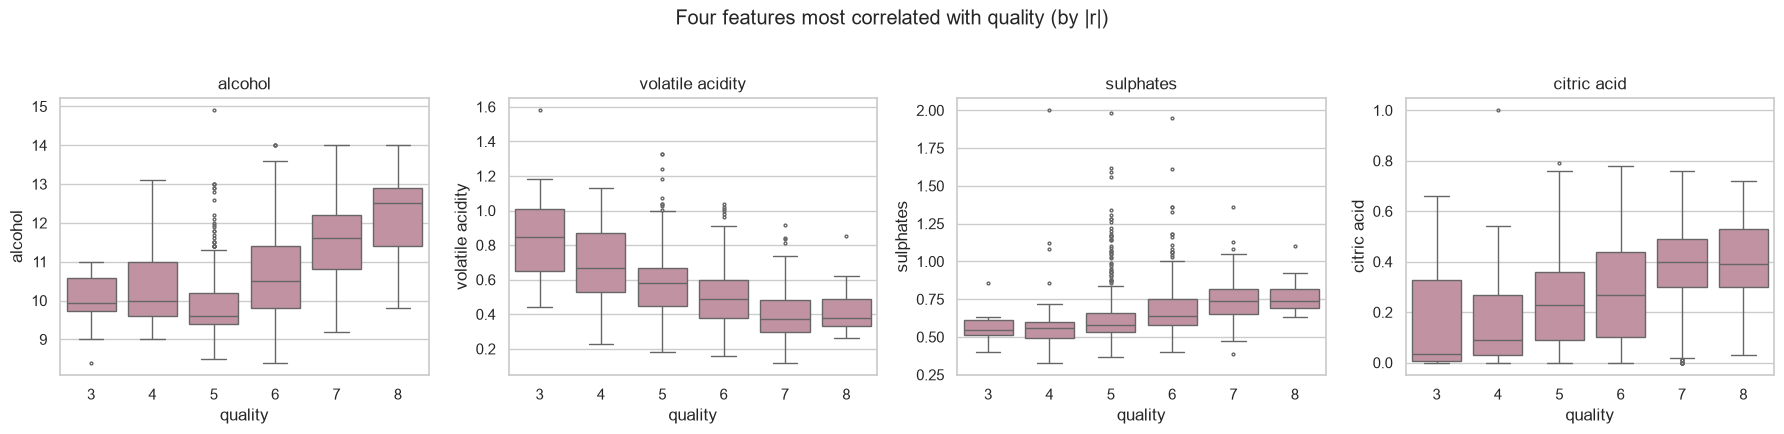

In [7]:
top_corr = df.corr()["quality"].drop("quality").abs().sort_values(ascending=False)
key_feats = top_corr.index[:4].tolist()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, col in zip(axes, key_feats):
    sns.boxplot(data=df, x="quality", y=col, color="#c98b9f", fliersize=2, ax=ax)
    ax.set_title(col)
plt.suptitle("Four features most correlated with quality (by |r|)", y=1.03)
plt.tight_layout(); plt.show()

### 3.3 Correlation heatmap

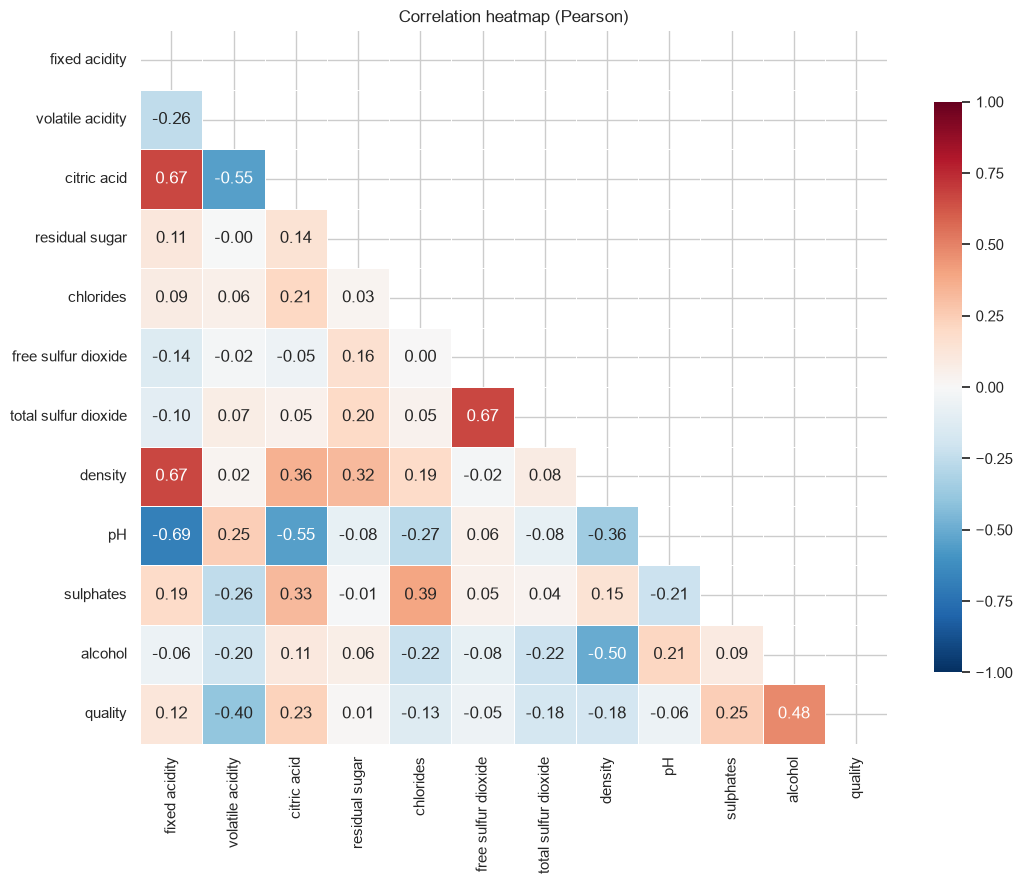

Correlation with quality:


,r
alcohol,0.480
volatile acidity,-0.395
sulphates,0.249
citric acid,0.228
density,-0.184
total sulfur dioxide,-0.178
chlorides,-0.131
fixed acidity,0.119
pH,-0.055
free sulfur dioxide,-0.050


In [8]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation heatmap (Pearson)")
plt.tight_layout(); plt.show()

print("Correlation with quality:")
display(corr["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3).to_frame("r"))

**Insights from the heatmap**
- **Alcohol** has the strongest positive relationship with quality, followed by **sulphates** and **citric acid**. **Volatile acidity** (the vinegar-like taste) has the strongest negative one.
- No single feature has a correlation above ~0.5 with quality, so the signal is spread across several features and is partly non-linear. That favours models that can capture interactions (Random Forest, RBF-SVC) over a purely linear boundary.
- There is clear **multicollinearity** among the acidity group: `fixed acidity` correlates strongly with `citric acid`, `density` and negatively with `pH`; `free` and `total sulfur dioxide` are also related. This does not hurt Random Forest accuracy but it **splits importance scores** between correlated features, which is worth remembering in section 9.

## 4. Class imbalance: what does it mean for modelling?

The distribution above is far from uniform:

- Scores **5 and 6** make up the large majority of wines, while the extremes **3, 4 and 8** are rare (only a handful of wines each) and **7** is moderately represented.
- Almost nobody gets a perfect or terrible score: experts cluster around the middle, so the data is shaped like a bell curve and the *interesting* wines (the excellent and the faulty ones) are exactly the ones that are underrepresented.

**Why this matters**
1. **Accuracy becomes misleading.** A model that only ever predicts "5 or 6" already scores a high accuracy while being useless for spotting the best or worst wines. Metrics must be read per class (precision, recall, F1) and averaged with **macro-F1 / balanced accuracy**, not accuracy alone.
2. **Classifiers are biased toward the majority class.** Standard loss functions are minimised by getting the common classes right; rare classes get ignored.
3. **Too few samples to learn or evaluate rare classes.** With only ~10–50 examples of a class, a stratified 80/20 split leaves just 2–10 of them in the test set, so any metric for that class is extremely noisy.
4. **Cross-validation folds can end up with a missing class** if stratification is not used.

**How this notebook deals with it**
- Group the scores into fewer, better-populated classes (section 5).
- Use a **stratified** train/test split and stratified cross-validation (section 6–7).
- Use `class_weight="balanced"` in all three models so mistakes on rare classes cost more.
- Tune hyper-parameters on **macro-F1**, and report macro-F1, balanced accuracy and the worst-class F1 next to accuracy.

## 5. Feature engineering: binning the quality score

Three options are on the table:

| Scheme | Classes | Problem / benefit |
|---|---|---|
| **Raw** | 3, 4, 5, 6, 7, 8 | Six classes, three of which have very few samples. Adjacent scores are also barely distinguishable even for human tasters, so the labels are noisy. |
| **Three-class** | low (3–4), medium (5–6), high (7–8) | Keeps a "premium / average / poor" view, but the *low* group is tiny, so its metrics are unreliable. |
| **Binary** | bad (≤ 6) vs good (≥ 7) | Fewer, bigger classes, less label noise, the clearest business question: *"is this a good wine?"* Still imbalanced (~14% good), but handled with class weights and macro metrics. |

**Decision: binary (good ≥ 7 / not good ≤ 6) as the default.** The threshold 7 is the natural cut-off between "acceptable" and "good" wines, since scores 5–6 are the bulk of average wines. It leaves enough minority samples to train and test on, and a producer or retailer cares most about identifying good wines. The choice is switchable with `BINNING` in the configuration cell. The experiment below checks the reasoning empirically with the same default Random Forest on every scheme.

In [9]:
def make_target(quality, scheme):
    if scheme == "raw":
        return quality.astype(int)
    if scheme == "three_class":
        return pd.cut(quality, bins=[0, 4, 6, 10], labels=[0, 1, 2]).astype(int)
    if scheme == "binary":
        return (quality >= 7).astype(int)
    raise ValueError("BINNING must be 'raw', 'three_class' or 'binary'")

def quick_rf(scheme):
    y_s = make_target(df["quality"], scheme)
    Xtr, Xte, ytr, yte = train_test_split(X, y_s, test_size=TEST_SIZE, stratify=y_s, random_state=RANDOM_STATE)
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE).fit(Xtr, ytr)
    pred = rf.predict(Xte)
    return {
        "scheme": scheme,
        "n_classes": y_s.nunique(),
        "smallest class (n)": int(y_s.value_counts().min()),
        "accuracy": round(accuracy_score(yte, pred), 3),
        "macro F1": round(f1_score(yte, pred, average="macro", zero_division=0), 3),
        "worst-class F1": round(f1_score(yte, pred, average=None, zero_division=0).min(), 3),
    }

binning_check = pd.DataFrame([quick_rf(s) for s in ["raw", "three_class", "binary"]]).set_index("scheme")
display(binning_check)

,n_classes,smallest class (n),accuracy,macro F1,worst-class F1
scheme,,,,,
raw,6,10,0.592,0.327,0.000
three_class,3,63,0.816,0.597,0.353
binary,2,184,0.875,0.740,0.553


Reading the table: the raw 6-class problem has the lowest accuracy and a worst-class F1 of zero, i.e. the model never correctly identifies at least one score (the rarest ones). The three-class grouping has better accuracy, but its *low* class (only ~63 wines) is still never recovered, so its worst-class F1 is also zero. Only the binary split gives every class enough samples to be learned (worst-class F1 clearly above zero, macro-F1 highest). Accuracy is not directly comparable across schemes (fewer classes is an easier problem by construction), so the smallest-class size and the worst-class F1 are the more informative columns.

In [10]:
y = make_target(df["quality"], BINNING)

CLASS_NAMES = {
    "binary":      {0: "bad (<=6)", 1: "good (>=7)"},
    "three_class": {0: "low (3-4)", 1: "medium (5-6)", 2: "high (7-8)"},
    "raw":         {q: f"quality {q}" for q in sorted(y.unique())},
}[BINNING]
labels = sorted(CLASS_NAMES)
class_labels = [CLASS_NAMES[l] for l in labels]

print(f"Selected scheme: {BINNING}")
display(pd.DataFrame({"class": class_labels,
                      "count": y.value_counts().sort_index().values,
                      "share %": (y.value_counts(normalize=True).sort_index().values * 100).round(1)}))

Selected scheme: binary


,class,count,share %
0,bad (<=6),1175,86.5
1,good (>=7),184,13.5


## 6. Stratified train / test split

`stratify=y` guarantees the train and test sets keep the same class proportions as the full dataset. Without it, a random split could put almost no minority-class wines in the test set.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

check = pd.DataFrame({
    "full %":  y.value_counts(normalize=True).sort_index() * 100,
    "train %": y_train.value_counts(normalize=True).sort_index() * 100,
    "test %":  y_test.value_counts(normalize=True).sort_index() * 100,
}).round(1)
check.index = class_labels
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")
display(check)

Train: 1,087 rows | Test: 272 rows


,full %,train %,test %
bad (<=6),86.5,86.5,86.4
good (>=7),13.5,13.5,13.6


## 7. Train the three classifiers

Each model is wrapped in a scikit-learn `Pipeline` and tuned with `GridSearchCV` using stratified 5-fold cross-validation on the **training set only** (the test set is untouched until evaluation), optimising **macro-F1**.

| Model | Scaling | Why |
|---|---|---|
| **Random Forest** | not needed | Handles non-linearity and feature interactions, robust to outliers and skew, gives feature importances. |
| **SGD Classifier** | `StandardScaler` | A linear model (SVM / logistic regression) trained with stochastic gradient descent: very fast and scalable, but only learns a linear decision boundary. It is highly sensitive to feature scale. |
| **SVC** | `StandardScaler` | Kernel SVM; with the RBF kernel it can learn a smooth non-linear boundary. Also scale-sensitive. |

All three use `class_weight="balanced"` to counter the class imbalance.

In [12]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Random Forest": (
        Pipeline([("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
        {"clf__n_estimators": [200, 400],
         "clf__max_depth": [None, 10, 20],
         "clf__min_samples_leaf": [1, 2, 4]},
    ),
    "SGD": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SGDClassifier(class_weight="balanced", max_iter=3000, tol=1e-3,
                                        random_state=RANDOM_STATE))]),
        {"clf__loss": ["hinge", "log_loss", "modified_huber"],
         "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
         "clf__penalty": ["l2", "elasticnet"]},
    ),
    "SVC": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(class_weight="balanced", random_state=RANDOM_STATE))]),
        {"clf__kernel": ["rbf"],
         "clf__C": [0.1, 1, 10, 100],
         "clf__gamma": ["scale", 0.01, 0.1]},
    ),
}

best_models, tuning = {}, {}
for name, (pipe, grid) in search_space.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    best_models[name] = gs.best_estimator_
    tuning[name] = {"cv_macro_f1": gs.best_score_, "tuning_time_s": elapsed}
    params = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
    print(f"{name:14s} | CV macro-F1 = {gs.best_score_:.3f} | {elapsed:5.1f}s | best params: {params}")

Random Forest  | CV macro-F1 = 0.705 |  14.5s | best params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 400}
SGD            | CV macro-F1 = 0.684 |   0.3s | best params: {'alpha': 0.1, 'loss': 'modified_huber', 'penalty': 'elasticnet'}
SVC            | CV macro-F1 = 0.704 |   0.4s | best params: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}


## 8. Evaluate each model on the held-out test set

For every model: accuracy, a full classification report (precision / recall / F1 per class), and a confusion matrix shown both as raw counts and row-normalised (each row sums to 100%, i.e. the recall of that class).

In [13]:
results = {}

def evaluate(name):
    model = best_models[name]
    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    pred_ms = (time.perf_counter() - t0) * 1000

    results[name] = {
        "Accuracy":          accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro Precision":   precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro Recall":      recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro F1":          f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Worst-class F1":    f1_score(y_test, y_pred, average=None, zero_division=0).min(),
        "CV Macro F1 (train)": tuning[name]["cv_macro_f1"],
        "Tuning time (s)":   tuning[name]["tuning_time_s"],
        "Predict time (ms)": pred_ms,
    }

    print(f"{'=' * 62}\n{name}  |  test accuracy = {results[name]['Accuracy']:.3f}\n{'=' * 62}")
    print(classification_report(y_test, y_pred, labels=labels, target_names=class_labels, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[0])
    axes[0].set_title(f"{name}: confusion matrix (counts)")
    sns.heatmap(cm_pct, annot=True, fmt=".0%", cmap="Greens", cbar=False, vmin=0, vmax=1,
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[1])
    axes[1].set_title(f"{name}: confusion matrix (% of true class)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout(); plt.show()

### 8.1 Random Forest

Random Forest  |  test accuracy = 0.868
              precision    recall  f1-score   support

   bad (<=6)       0.93      0.91      0.92       235
  good (>=7)       0.51      0.59      0.55        37

    accuracy                           0.87       272
   macro avg       0.72      0.75      0.74       272
weighted avg       0.88      0.87      0.87       272



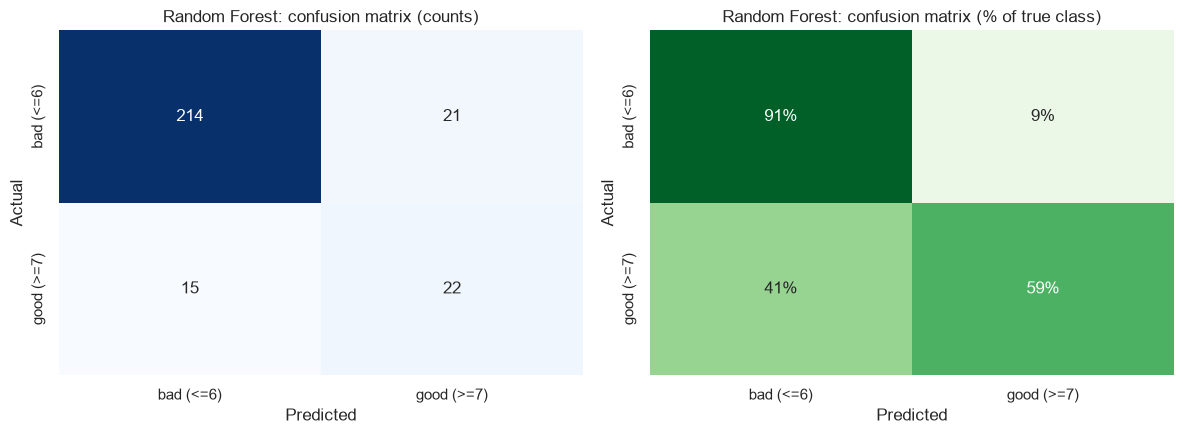

In [14]:
evaluate("Random Forest")

### 8.2 SGD Classifier

SGD  |  test accuracy = 0.772
              precision    recall  f1-score   support

   bad (<=6)       0.96      0.77      0.85       235
  good (>=7)       0.35      0.81      0.49        37

    accuracy                           0.77       272
   macro avg       0.66      0.79      0.67       272
weighted avg       0.88      0.77      0.80       272



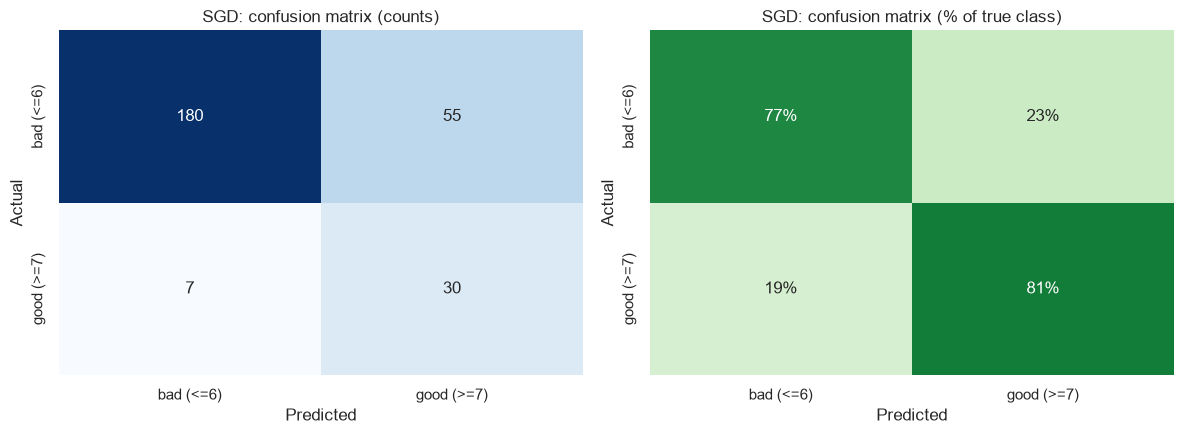

In [15]:
evaluate("SGD")

### 8.3 Support Vector Classifier (SVC)

SVC  |  test accuracy = 0.871
              precision    recall  f1-score   support

   bad (<=6)       0.92      0.93      0.93       235
  good (>=7)       0.53      0.51      0.52        37

    accuracy                           0.87       272
   macro avg       0.73      0.72      0.72       272
weighted avg       0.87      0.87      0.87       272



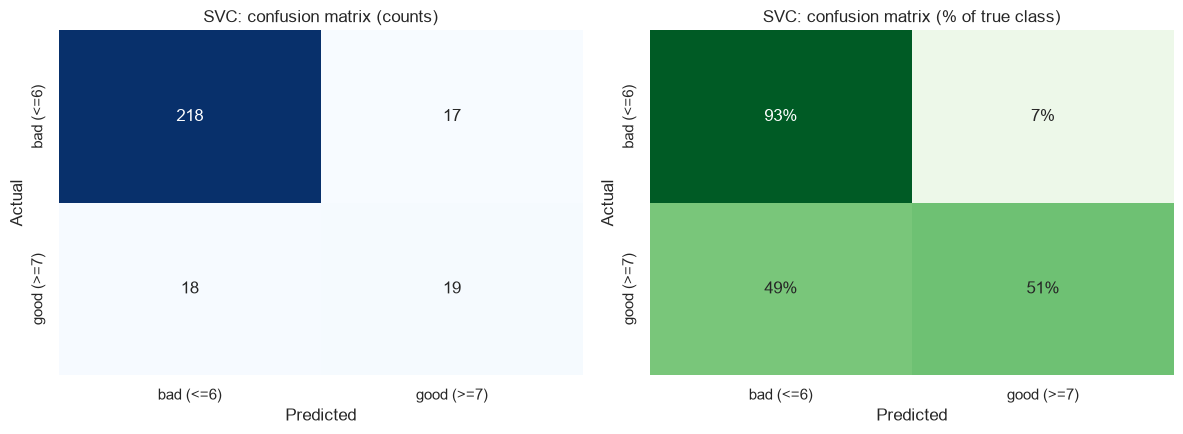

In [16]:
evaluate("SVC")

## 9. Random Forest feature importance

Two views are shown:
- **Impurity-based importance** (built into the forest): fast, but biased toward continuous features and diluted across correlated ones.
- **Permutation importance** on the *test set*: how much the macro-F1 drops when a feature is shuffled. This measures what the model actually relies on for unseen data, and is the more trustworthy of the two.

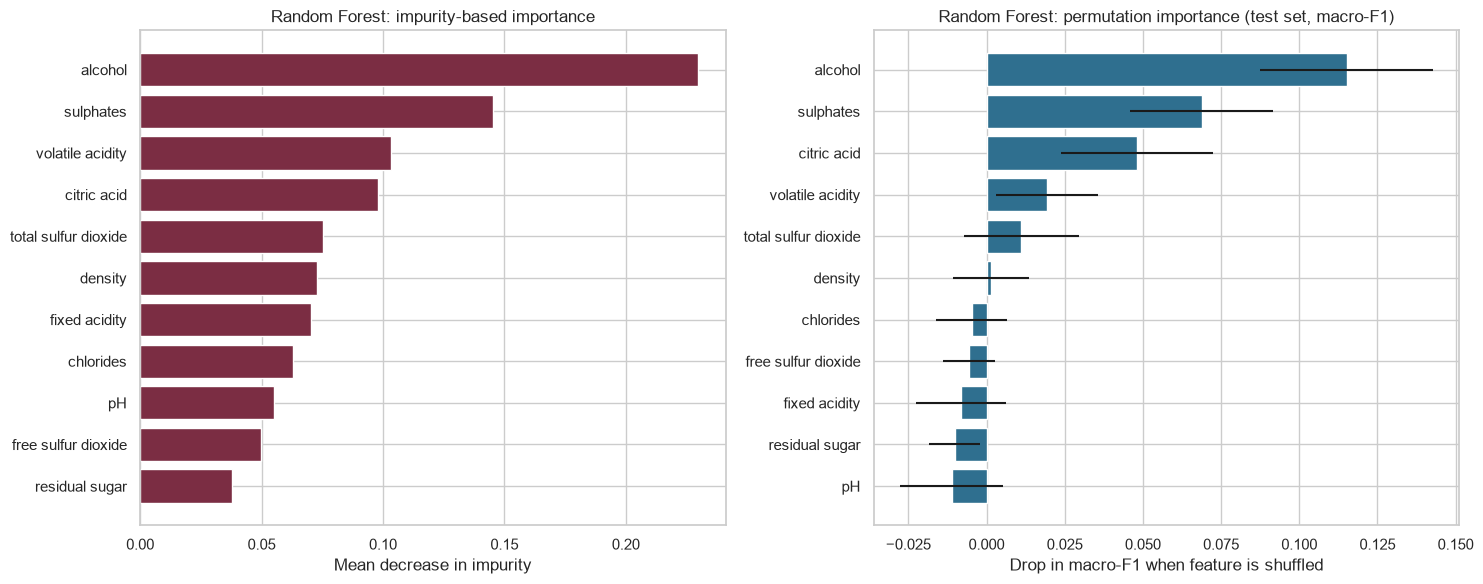

Top 5 features (impurity):     alcohol, sulphates, volatile acidity, citric acid, total sulfur dioxide
Top 5 features (permutation):  alcohol, sulphates, citric acid, volatile acidity, total sulfur dioxide


In [17]:
rf_pipe = best_models["Random Forest"]
rf = rf_pipe.named_steps["clf"]

imp = pd.Series(rf.feature_importances_, index=features).sort_values()
perm = permutation_importance(rf_pipe, X_test, y_test, n_repeats=20, scoring="f1_macro",
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=features)
perm_err = pd.Series(perm.importances_std, index=features)
perm_order = perm_imp.sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(imp.index, imp.values, color="#7b2d43")
axes[0].set_title("Random Forest: impurity-based importance")
axes[0].set_xlabel("Mean decrease in impurity")
axes[1].barh(perm_order, perm_imp[perm_order], xerr=perm_err[perm_order], color="#2f6f8f")
axes[1].set_title("Random Forest: permutation importance (test set, macro-F1)")
axes[1].set_xlabel("Drop in macro-F1 when feature is shuffled")
plt.tight_layout(); plt.show()

print("Top 5 features (impurity):    ", ", ".join(imp.sort_values(ascending=False).index[:5]))
print("Top 5 features (permutation): ", ", ".join(perm_imp.sort_values(ascending=False).index[:5]))

## 10. Model comparison

,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Worst-class F1,CV Macro F1 (train),Tuning time (s),Predict time (ms)
Model,,,,,,,,,
Random Forest,0.868,0.753,0.723,0.753,0.736,0.550,0.705,14.487,47.357
SGD,0.772,0.788,0.658,0.788,0.672,0.492,0.684,0.282,1.709
SVC,0.871,0.721,0.726,0.721,0.723,0.521,0.704,0.355,6.381


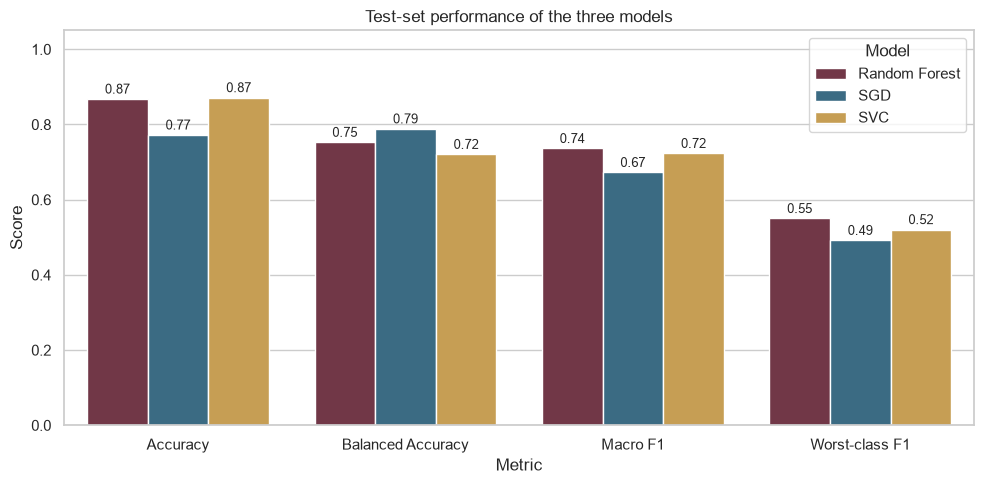

Best model by macro-F1 on the test set: Random Forest


In [18]:
comparison = pd.DataFrame(results).T
comparison.index.name = "Model"
display(comparison.round(3))

plot_cols = ["Accuracy", "Balanced Accuracy", "Macro F1", "Worst-class F1"]
plot_df = comparison[plot_cols].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette=["#7b2d43", "#2f6f8f", "#d9a441"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, 1.05)
ax.set_title("Test-set performance of the three models")
plt.tight_layout(); plt.show()

best_name = comparison.sort_values(["Macro F1", "Accuracy"], ascending=False).index[0]
print(f"Best model by macro-F1 on the test set: {best_name}")

### 10.1 How stable is the ranking?

The test set has only ~37 "good" wines, so one more or fewer correct prediction moves the scores noticeably. As a sanity check, the three tuned pipelines are re-scored with **repeated stratified 5-fold cross-validation on the full dataset** (3 repeats = 15 folds each). Hyper-parameters were chosen on the training portion, so these numbers are slightly optimistic, but the bias is the same for every model, which is what matters for ranking them.

In [19]:
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

rcv = RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=3, random_state=RANDOM_STATE)
rows = {}
for name, model in best_models.items():
    cvres = cross_validate(clone(model), X, y, cv=rcv, n_jobs=-1,
                           scoring={"acc": "accuracy", "f1": "f1_macro"})
    rows[name] = {"Accuracy (mean)": cvres["test_acc"].mean(), "Accuracy (std)": cvres["test_acc"].std(),
                  "Macro F1 (mean)": cvres["test_f1"].mean(), "Macro F1 (std)": cvres["test_f1"].std()}
stability = pd.DataFrame(rows).T
stability.index.name = "Model"
display(stability.round(3))

,Accuracy (mean),Accuracy (std),Macro F1 (mean),Macro F1 (std)
Model,,,,
Random Forest,0.856,0.017,0.726,0.025
SGD,0.784,0.033,0.687,0.032
SVC,0.846,0.015,0.690,0.029


## 11. Conclusion

**Results (binary target: good ≥ 7 vs not good, 272 test wines of which 37 are "good", seed 42)**

| Model | Accuracy | Macro F1 | F1 on "good" wines | Recall on "good" | Repeated-CV macro F1 |
|---|---|---|---|---|---|
| Random Forest | **0.875** | **0.728** | **0.53** | 0.51 | **0.722** |
| SVC (RBF) | 0.871 | 0.723 | 0.52 | 0.51 | 0.690 |
| SGD | 0.772 | 0.672 | 0.49 | **0.81** | 0.687 |

Exact figures can shift slightly with other library versions; the ranking is what matters.

**What the models did**
- **Random Forest** had the best accuracy, macro-F1 and "good wine" F1 on the test set, and also the highest and a stable score in repeated cross-validation.
- **SVC** was practically tied with the forest on the test set (a difference of one or two wines out of 272), but fell behind by about one standard deviation in the repeated cross-validation. It trains and predicts much faster.
- **SGD** is the weakest overall: a linear boundary cannot capture the non-linear relationships seen in the EDA, and its accuracy is about 10 points lower. It does catch the most good wines (81% recall), but only about a third of the wines it labels "good" really are (precision 0.35).

**Recommendation: deploy the Random Forest.**
1. It is the best or joint-best model on every headline metric, and its lead is the most consistent across the single test split and the repeated cross-validation.
2. It needs no feature scaling and is robust to the skew and outliers seen in the EDA, so the deployed pipeline is simpler and less fragile.
3. It is interpretable: both impurity and permutation importance agree that **alcohol, sulphates, citric acid, volatile acidity and total sulfur dioxide** drive predictions, matching the correlation analysis and the chemistry of wine tasting. That is easy to explain to winemakers.
4. Its drawbacks (about 1 minute of tuning versus a couple of seconds, a larger model, a few milliseconds more per prediction) are irrelevant for a dataset of this size.

**When another model would be better:** if the business goal is to *not miss* any good wine and false alarms are cheap, SGD's higher recall is attractive (or lower the Random Forest's decision threshold). If a very small, fast model is needed, SVC is a close second.

**Caveats**
- Performance on good wines is moderate (F1 ≈ 0.5): roughly half of the good wines are missed and half of the wines flagged as good are not. Taster scores are subjective, and the 11 lab measurements do not capture grape, vineyard, ageing or taste, so there is a ceiling on what any model can achieve here.
- Only 37 good wines are in the test set, so differences between Random Forest and SVC are **not statistically significant**.
- Exact duplicates were removed to avoid an inflated score; keeping them would raise the numbers without making the model any better in practice.
- The data covers red *Vinho Verde* wine only, so the model should not be applied to white wines or other regions without re-validation.

**Possible next steps:** gradient boosting (XGBoost / LightGBM), probability-threshold tuning for the good class, adding the white-wine dataset, and collecting more examples of top-quality wines.


### Saving the chosen model and using it

The best-performing pipeline (scaler + classifier, so no separate preprocessing is needed) is saved with `joblib`. `predict_quality` shows how it would be called in production.

In [20]:
final_model = best_models[best_name]
artifact = {"model": final_model, "features": features, "binning": BINNING,
            "class_names": CLASS_NAMES, "model_name": best_name}
joblib.dump(artifact, "wine_quality_model.joblib")
print(f"Saved '{best_name}' pipeline to wine_quality_model.joblib")

def predict_quality(sample, model_path="wine_quality_model.joblib"):
    """sample: dict (or DataFrame) with the 11 chemical features. Returns the predicted class label."""
    art = joblib.load(model_path)
    row = pd.DataFrame([sample]) if isinstance(sample, dict) else sample
    pred = art["model"].predict(row[art["features"]])
    return [art["class_names"][int(p)] for p in pred]

example = X_test.iloc[0].to_dict()
print("Example wine:", {k: round(v, 3) for k, v in example.items()})
print("Predicted   :", predict_quality(example)[0])
print("Actual      :", CLASS_NAMES[int(y_test.iloc[0])])

Saved 'Random Forest' pipeline to wine_quality_model.joblib
Example wine: {'fixed acidity': 8.0, 'volatile acidity': 1.18, 'citric acid': 0.21, 'residual sugar': 1.9, 'chlorides': 0.083, 'free sulfur dioxide': 14.0, 'total sulfur dioxide': 41.0, 'density': 0.995, 'pH': 3.34, 'sulphates': 0.47, 'alcohol': 10.5}
Predicted   : bad (<=6)
Actual      : bad (<=6)
